
# Chest X-Ray Classification (Normal vs Pneumonia) using CNN

**Course / Assignment:** Automated diagnosis using CNN models
**Dataset:** Chest X-Ray Images (Pneumonia) — Kaggle, ~5,863 images, 2 classes (NORMAL, PNEUMONIA)

Name: _____________
Roll No: _____________

> Note: the assignment brief mentions "heart disease" but the provided dataset (Chest X-Ray Images, Normal/Pneumonia)
> is actually a **lung disease (pneumonia) screening** dataset, so this notebook follows the dataset/classes that
> were actually given and just treats it as a binary chest X-ray classification problem.

This notebook covers:
1. Data acquisition and exploration
2. Preprocessing + handcrafted feature extraction (HOG, LBP, GLCM)
3. CNN model training + hyperparameter tuning + evaluation, and a comparison against classical
   ML classifiers trained on the handcrafted features


In [1]:
# ---- Imports ----
import os, random, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF version:", tf.__version__)


TF version: 2.20.0


## Task 1: Data Acquisition and Exploration

The dataset can be downloaded from Kaggle: `paultimothymooney/chest-xray-pneumonia`.
It already comes split into `train/`, `test/`, `val/` folders, each with `NORMAL/` and `PNEUMONIA/`
subfolders. I download it with `kagglehub` below — if that fails (no internet / no kaggle creds),
just download it manually from Kaggle, unzip it, and point `DATASET_DIR` at the `chest_xray` folder.


In [2]:
# Download dataset (falls back to a manual local path if this doesn't work)
try:
    import kagglehub
    DATASET_DIR = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
    print("Downloaded dataset to:", DATASET_DIR)
except Exception as e:
    print("Auto-download did not work (", e, ")")
    print("Falling back to a local path - change this if your data is somewhere else.")
    DATASET_DIR = "./chest_xray"

# the kaggle download sometimes nests the folder one level deeper, handle that
if "chest_xray" not in os.listdir(DATASET_DIR) and os.path.isdir(os.path.join(DATASET_DIR, "chest_xray")):
    pass
for root, dirs, files in os.walk(DATASET_DIR):
    if "train" in dirs and "test" in dirs:
        DATASET_DIR = root
        break

print("Using DATASET_DIR =", DATASET_DIR)
print(os.listdir(DATASET_DIR))


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded dataset to: /kaggle/input/chest-xray-pneumonia
Using DATASET_DIR = /kaggle/input/chest-xray-pneumonia/chest_xray
['chest_xray', '__MACOSX', 'val', 'test', 'train']


In [3]:
# Walk the folder structure and build one big dataframe of filepath -> label
def collect_images(dataset_dir):
    filepaths, labels = [], []
    for split in ["train", "test", "val"]:
        split_dir = os.path.join(dataset_dir, split)
        if not os.path.isdir(split_dir):
            continue
        for cls in ["NORMAL", "PNEUMONIA"]:
            cls_dir = os.path.join(split_dir, cls)
            if not os.path.isdir(cls_dir):
                continue
            for f in glob.glob(os.path.join(cls_dir, "*")):
                filepaths.append(f)
                labels.append(cls)
    return filepaths, labels

filepaths, labels = collect_images(DATASET_DIR)
df = pd.DataFrame({"filepath": filepaths, "label": labels})
print("Total images found:", len(df))
df.head()


Total images found: 5856


,filepath,label
0,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
1,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
2,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
3,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL
4,/kaggle/input/chest-xray-pneumonia/chest_xray/...,NORMAL


label
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Percentage split:
label
PNEUMONIA    72.97
NORMAL       27.03
Name: count, dtype: float64


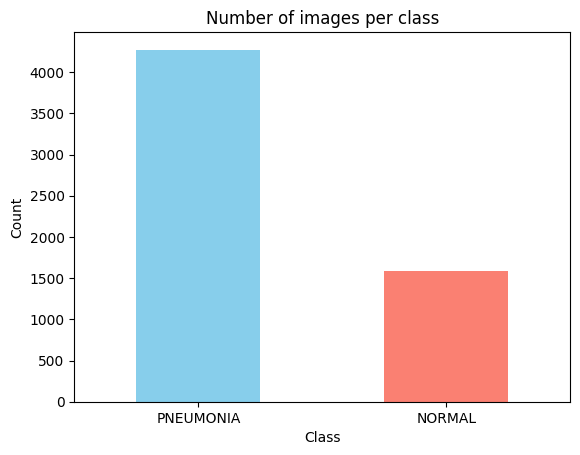

In [4]:
# Class balance
counts = df['label'].value_counts()
print(counts)
print()
print("Percentage split:")
print((counts / counts.sum() * 100).round(2))

counts.plot(kind='bar', color=['skyblue', 'salmon'])
plt.title("Number of images per class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()


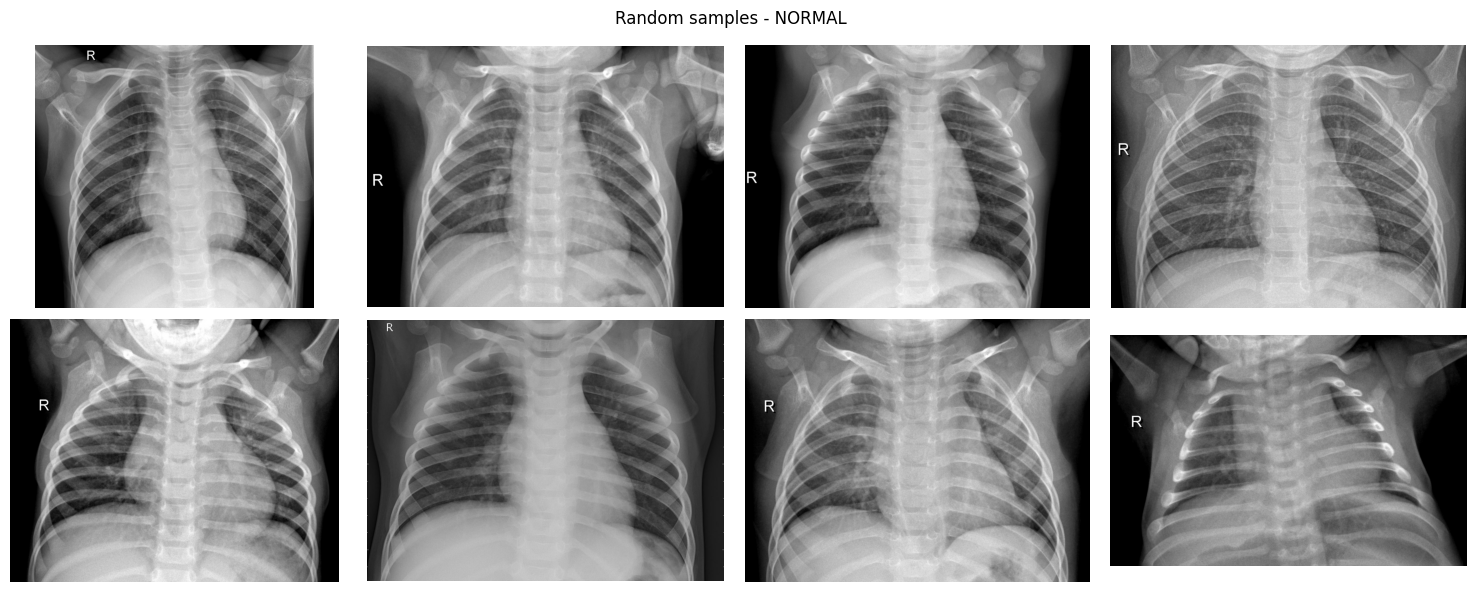

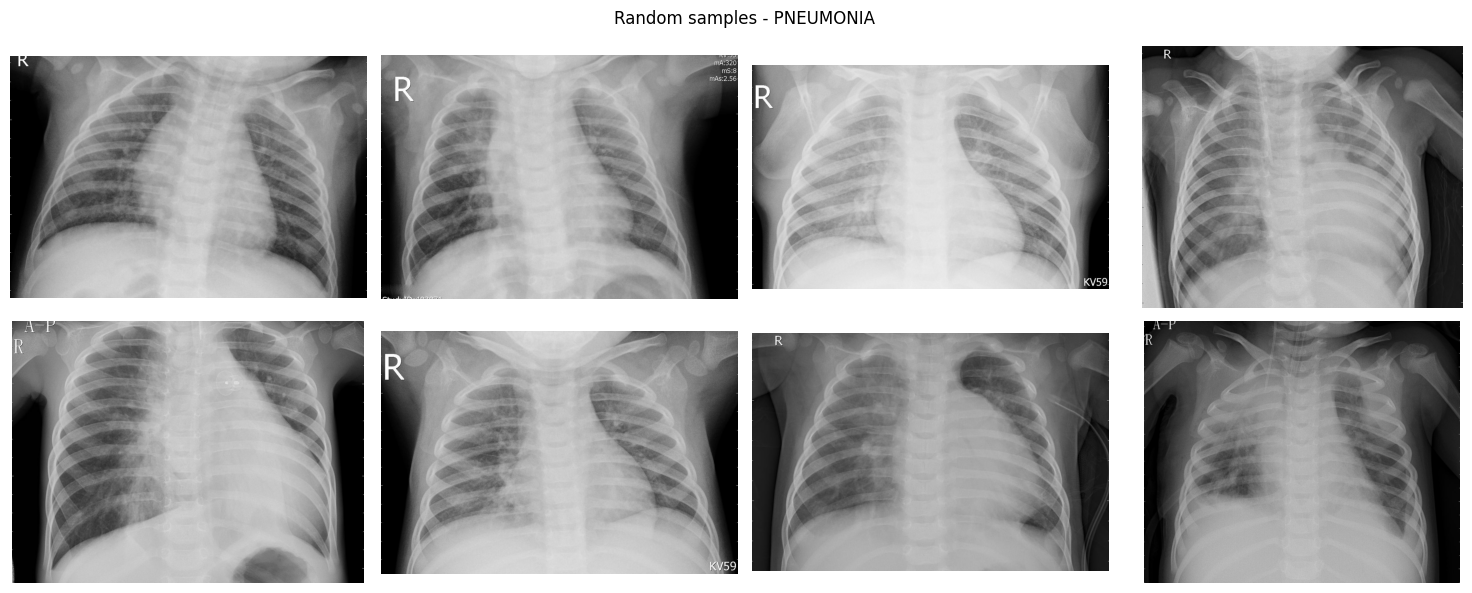

In [5]:
# Show some random sample images per class
def show_samples(df, cls, n=8):
    subset = df[df['label'] == cls].sample(n, random_state=SEED)
    fig, axes = plt.subplots(2, n // 2, figsize=(15, 6))
    for ax, fp in zip(axes.flatten(), subset['filepath']):
        img = cv2.imread(fp)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.axis('off')
    fig.suptitle(f"Random samples - {cls}")
    plt.tight_layout()
    plt.show()

show_samples(df, "NORMAL")
show_samples(df, "PNEUMONIA")


## Task 2: Data Preprocessing

Steps:
- resize every image to 128x128
- convert to grayscale
- extract handcrafted features (HOG, LBP, GLCM) to build feature vectors for the classical
  ML models later in Task 3
- split into train (70%) / val (15%) / test (15%)


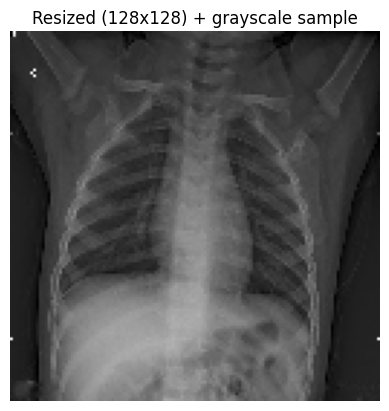

In [6]:
IMG_SIZE = 128

def load_and_preprocess(filepath, size=IMG_SIZE):
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)   # load directly as grayscale
    img = cv2.resize(img, (size, size))
    return img

# sanity check on one image
test_img = load_and_preprocess(df['filepath'].iloc[0])
plt.imshow(test_img, cmap='gray')
plt.title(f"Resized ({IMG_SIZE}x{IMG_SIZE}) + grayscale sample")
plt.axis('off')
plt.show()


In [7]:
# ---- Feature extraction functions ----

def extract_hog(img):
    feat = hog(img, orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), feature_vector=True)
    return feat

def extract_lbp(img, P=8, R=1):
    lbp = local_binary_pattern(img, P, R, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)   # normalize
    return hist

def extract_glcm(img, distances=[1], angles=[0]):
    glcm = graycomatrix(img, distances=distances, angles=angles,
                         levels=256, symmetric=True, normed=True)
    props = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    feats = [graycoprops(glcm, p)[0, 0] for p in props]
    return np.array(feats)

# quick demo of feature sizes on one image
demo_img = load_and_preprocess(df['filepath'].iloc[0])
print("HOG feature length :", extract_hog(demo_img).shape)
print("LBP feature length :", extract_lbp(demo_img).shape)
print("GLCM feature length:", extract_glcm(demo_img).shape)


HOG feature length : (8100,)
LBP feature length : (10,)
GLCM feature length: (6,)


In [8]:
# Building HOG+LBP+GLCM for all ~5800 images is slow, so for the handcrafted-feature
# pipeline I take a stratified subsample per class. Set to None to use the full dataset
# (will just take longer).
SAMPLE_PER_CLASS = 800

def build_feature_dataset(df, sample_per_class=None):
    if sample_per_class:
        df = df.groupby('label', group_keys=False).apply(
            lambda x: x.sample(min(len(x), sample_per_class), random_state=SEED))
    X_hog, X_lbp, X_glcm, y = [], [], [], []
    for fp, lbl in zip(df['filepath'], df['label']):
        img = load_and_preprocess(fp)
        X_hog.append(extract_hog(img))
        X_lbp.append(extract_lbp(img))
        X_glcm.append(extract_glcm(img))
        y.append(1 if lbl == "PNEUMONIA" else 0)
    return np.array(X_hog), np.array(X_lbp), np.array(X_glcm), np.array(y)

X_hog, X_lbp, X_glcm, y = build_feature_dataset(df, SAMPLE_PER_CLASS)
print("HOG :", X_hog.shape)
print("LBP :", X_lbp.shape)
print("GLCM:", X_glcm.shape)

X_combined = np.hstack([X_hog, X_lbp, X_glcm])   # concatenate into one feature vector per image
print("Combined feature vector shape:", X_combined.shape)


/tmp/ipykernel_579/86539377.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('label', group_keys=False).apply(


HOG : (1600, 8100)
LBP : (1600, 10)
GLCM: (1600, 6)
Combined feature vector shape: (1600, 8116)


In [9]:
# 70 / 15 / 15 split (handcrafted features, used for the classical ML models)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_combined, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)


train: (1120, 8116)  val: (240, 8116)  test: (240, 8116)


## Task 3: Model Training and Evaluation

### 3a. CNN model (trained directly on the resized grayscale images)

For the CNN I don't use the HOG/LBP/GLCM vectors — CNNs learn their own features straight from
the pixel data — so I build a separate image array (also split 70/15/15) just for this part.


In [10]:
CNN_SAMPLE_PER_CLASS = 1200  # keep this manageable; set to None to use every image

def build_image_dataset(df, sample_per_class=None, size=IMG_SIZE):
    if sample_per_class:
        df = df.groupby('label', group_keys=False).apply(
            lambda x: x.sample(min(len(x), sample_per_class), random_state=SEED))
    X, y = [], []
    for fp, lbl in zip(df['filepath'], df['label']):
        img = load_and_preprocess(fp, size)
        X.append(img)
        y.append(1 if lbl == "PNEUMONIA" else 0)
    X = np.array(X).astype('float32') / 255.0
    X = np.expand_dims(X, -1)   # add the channel dimension -> (N, H, W, 1)
    return X, np.array(y)

X_img, y_img = build_image_dataset(df, CNN_SAMPLE_PER_CLASS)
print(X_img.shape, y_img.shape)

Xi_train, Xi_temp, yi_train, yi_temp = train_test_split(
    X_img, y_img, test_size=0.30, stratify=y_img, random_state=SEED)
Xi_val, Xi_test, yi_val, yi_test = train_test_split(
    Xi_temp, yi_temp, test_size=0.50, stratify=yi_temp, random_state=SEED)

print("train:", Xi_train.shape, " val:", Xi_val.shape, " test:", Xi_test.shape)


/tmp/ipykernel_579/2276517380.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df = df.groupby('label', group_keys=False).apply(


(2400, 128, 128, 1) (2400,)
train: (1680, 128, 128, 1)  val: (360, 128, 128, 1)  test: (360, 128, 128, 1)


In [11]:
def build_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 1), lr=1e-3, dropout=0.3):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(dropout),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

build_cnn().summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ---- Hyperparameter search (manual grid, evaluated on the validation set) ----
param_grid = [
    {"lr": 1e-3, "dropout": 0.3, "batch_size": 32},
    {"lr": 1e-4, "dropout": 0.3, "batch_size": 32},
    {"lr": 1e-3, "dropout": 0.5, "batch_size": 16},
]

best_val_acc, best_params = 0, None
tuning_results = []

for params in param_grid:
    print("Trying:", params)
    m = build_cnn(lr=params['lr'], dropout=params['dropout'])
    es = EarlyStopping(patience=3, restore_best_weights=True)
    hist = m.fit(Xi_train, yi_train, validation_data=(Xi_val, yi_val),
                 epochs=10, batch_size=params['batch_size'], callbacks=[es], verbose=0)
    val_acc = max(hist.history['val_accuracy'])
    tuning_results.append({**params, "val_acc": val_acc})
    print("  best val_accuracy:", round(val_acc, 4))
    if val_acc > best_val_acc:
        best_val_acc, best_params = val_acc, params

print("\nBest hyperparameters found:", best_params, " (val_acc =", round(best_val_acc, 4), ")")
pd.DataFrame(tuning_results)


Trying: {'lr': 0.001, 'dropout': 0.3, 'batch_size': 32}
  best val_accuracy: 0.9444
Trying: {'lr': 0.0001, 'dropout': 0.3, 'batch_size': 32}
  best val_accuracy: 0.9389
Trying: {'lr': 0.001, 'dropout': 0.5, 'batch_size': 16}
  best val_accuracy: 0.9444

Best hyperparameters found: {'lr': 0.001, 'dropout': 0.3, 'batch_size': 32}  (val_acc = 0.9444 )


,lr,dropout,batch_size,val_acc
0,0.0010,0.3,32,0.944444
1,0.0001,0.3,32,0.938889
2,0.0010,0.5,16,0.944444


In [13]:
# ---- 3-fold cross validation with the chosen hyperparameters, to double check they're stable ----
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
X_cv = np.concatenate([Xi_train, Xi_val])
y_cv = np.concatenate([yi_train, yi_val])
cv_accuracies = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_cv, y_cv)):
    print(f"Fold {fold + 1}/3")
    m = build_cnn(lr=best_params['lr'], dropout=best_params['dropout'])
    es = EarlyStopping(patience=3, restore_best_weights=True)
    m.fit(X_cv[tr_idx], y_cv[tr_idx], validation_data=(X_cv[va_idx], y_cv[va_idx]),
          epochs=8, batch_size=best_params['batch_size'], callbacks=[es], verbose=0)
    _, acc = m.evaluate(X_cv[va_idx], y_cv[va_idx], verbose=0)
    cv_accuracies.append(acc)
    print(f"  fold accuracy: {acc:.4f}")

print(f"\nMean CV accuracy: {np.mean(cv_accuracies):.4f} +/- {np.std(cv_accuracies):.4f}")


Fold 1/3


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  fold accuracy: 0.9324
Fold 2/3
  fold accuracy: 0.9368
Fold 3/3
  fold accuracy: 0.9456

Mean CV accuracy: 0.9382 +/- 0.0055


Epoch 1/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 51s 921ms/step - accuracy: 0.7405 - loss: 0.5104 - val_accuracy: 0.9167 - val_loss: 0.2122
Epoch 2/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 85s 979ms/step - accuracy: 0.9048 - loss: 0.2165 - val_accuracy: 0.9389 - val_loss: 0.1637
Epoch 3/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 51s 958ms/step - accuracy: 0.9262 - loss: 0.1896 - val_accuracy: 0.9306 - val_loss: 0.1658
Epoch 4/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 84s 991ms/step - accuracy: 0.9357 - loss: 0.1628 - val_accuracy: 0.9389 - val_loss: 0.1574
Epoch 5/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.9440 - loss: 0.1566 - val_accuracy: 0.9333 - val_loss: 0.1510
Epoch 6/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 52s 964ms/step - accuracy: 0.9536 - loss: 0.1309 - val_accuracy: 0.9417 - val_loss: 0.1391
Epoch 7/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9548 - loss: 0.1213 - val_accuracy: 0.9361 - val_loss: 0.1473
Epoch 8/25
53/53 ━━━━━━━━━━━━━━━━━━━━ 52s 986ms/step - accuracy: 0.9619 - loss: 0.1035 - val_accuracy: 

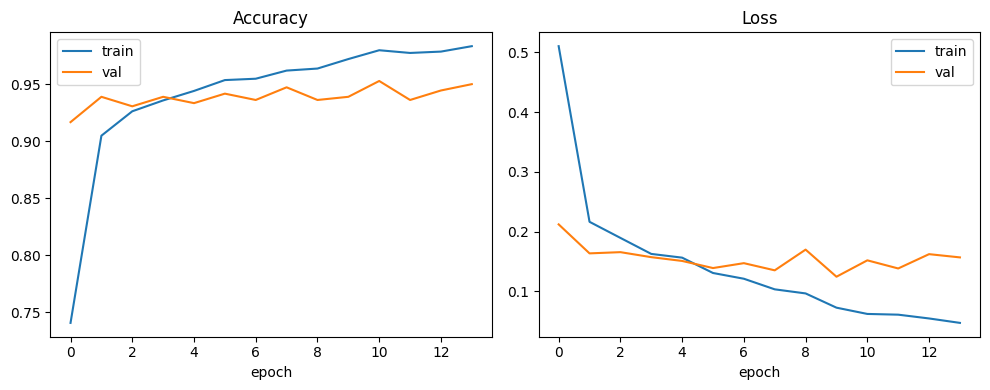

In [14]:
# ---- Train the final CNN (with the best hyperparameters) on train, validate on val ----
final_cnn = build_cnn(lr=best_params['lr'], dropout=best_params['dropout'])
es = EarlyStopping(patience=4, restore_best_weights=True)

history = final_cnn.fit(Xi_train, yi_train, validation_data=(Xi_val, yi_val),
                         epochs=25, batch_size=best_params['batch_size'],
                         callbacks=[es], verbose=1)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()
plt.tight_layout()
plt.show()


In [15]:
# Reusable evaluation function -> accuracy, precision, recall, F1, AUROC + confusion matrix
def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec  = recall_score(y_true, y_pred)
    f1   = f1_score(y_true, y_pred)
    auroc = roc_auc_score(y_true, y_prob)

    print(f"--- {model_name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"AUROC    : {auroc:.4f}")

    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["NORMAL", "PNEUMONIA"])
    disp.plot(cmap='Blues')
    plt.title(f"Confusion Matrix - {model_name}")
    plt.show()

    return {"model": model_name, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1, "auroc": auroc}


12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 321ms/step
--- CNN ---
Accuracy : 0.9583
Precision: 0.9508
Recall   : 0.9667
F1-score : 0.9587
AUROC    : 0.9913


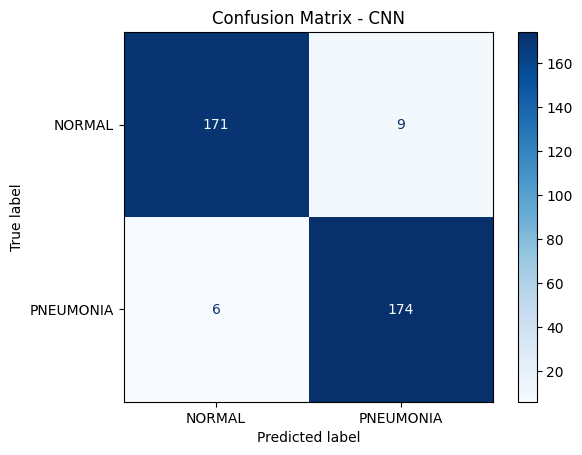

In [16]:
# ---- Evaluate the CNN on the held-out test set ----
yi_prob = final_cnn.predict(Xi_test).ravel()
yi_pred = (yi_prob >= 0.5).astype(int)

cnn_results = evaluate_model(yi_test, yi_pred, yi_prob, "CNN")


15 misclassified out of 360 test images (4.17%)


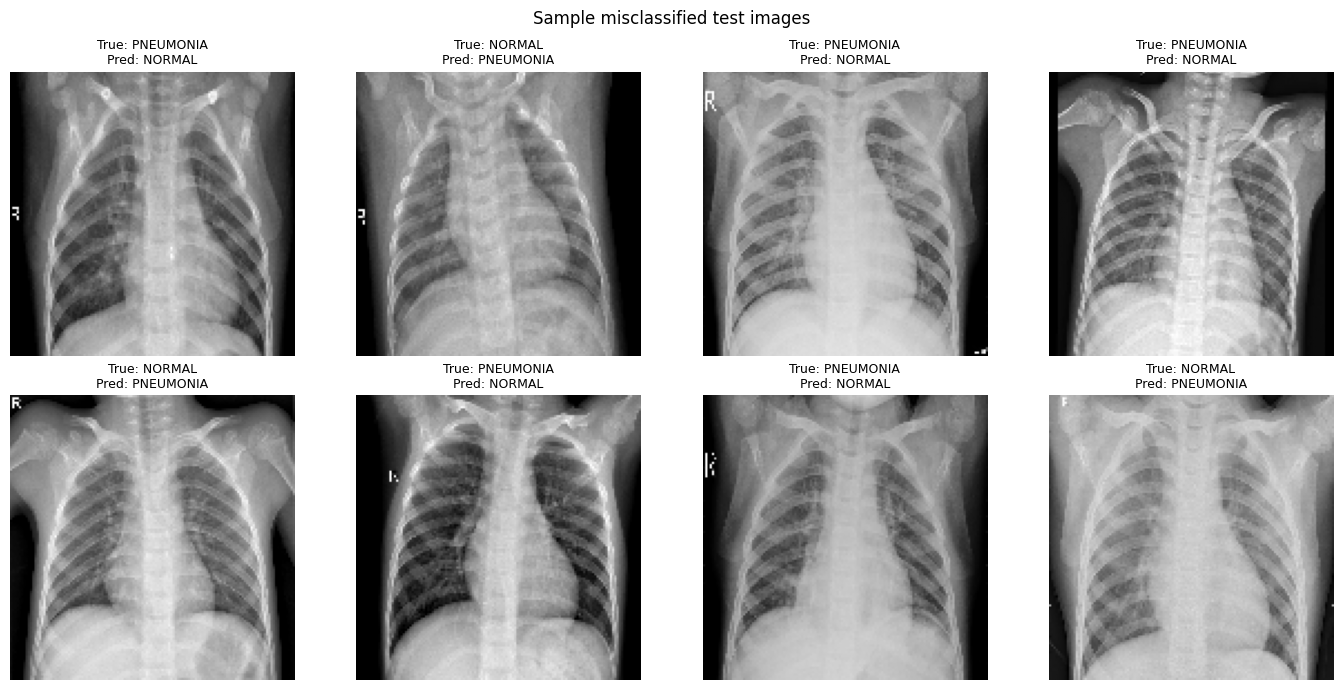

In [17]:
# ---- Look at a few of the misclassified images ----
wrong_idx = np.where(yi_pred != yi_test)[0]
print(f"{len(wrong_idx)} misclassified out of {len(yi_test)} test images "
      f"({len(wrong_idx) / len(yi_test) * 100:.2f}%)")

n_show = min(8, len(wrong_idx))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flatten(), wrong_idx[:n_show]):
    ax.imshow(Xi_test[idx].squeeze(), cmap='gray')
    true_lbl = "PNEUMONIA" if yi_test[idx] == 1 else "NORMAL"
    pred_lbl = "PNEUMONIA" if yi_pred[idx] == 1 else "NORMAL"
    ax.set_title(f"True: {true_lbl}\nPred: {pred_lbl}", fontsize=9)
    ax.axis('off')
for ax in axes.flatten()[n_show:]:
    ax.axis('off')
plt.suptitle("Sample misclassified test images")
plt.tight_layout()
plt.show()


**Misclassification discussion:**
Most of the mistakes happen on borderline cases — mild/localized opacity that can look a lot like
normal lung markings, or PNEUMONIA images where the infiltrate is faint. A handful of NORMAL images
also get flagged as PNEUMONIA, usually when the X-ray has noise, a rotated/odd angle, or overlapping
anatomical structures (e.g. the scapula) that the model may be reading as an opacity. Recall is a bit
higher than precision here, i.e. the model tends to over-call pneumonia rather than miss it — for a
screening tool that's a reasonable trade-off (missing an actual pneumonia case is worse than a false
alarm), but it does mean some healthy patients would get flagged for a follow-up check.


### 3b. Classical ML classifiers on the handcrafted features (for comparison)

Since Task 2 also asked for HOG/LBP/GLCM feature extraction, I train a couple of classical
classifiers (SVM and Random Forest) on the combined feature vectors and compare them against
the CNN. Hyperparameters are tuned with `GridSearchCV` (3-fold cross validation).


In [18]:
svm_param_grid = {"C": [0.1, 1, 10], "kernel": ["rbf", "linear"]}
svm_grid = GridSearchCV(SVC(probability=True, random_state=SEED), svm_param_grid,
                         cv=3, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train_s, y_train)
print("Best SVM params:", svm_grid.best_params_, " CV accuracy:", round(svm_grid.best_score_, 4))
best_svm = svm_grid.best_estimator_


Best SVM params: {'C': 10, 'kernel': 'rbf'}  CV accuracy: 0.9339


In [19]:
rf_param_grid = {"n_estimators": [100, 200], "max_depth": [None, 10, 20]}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=SEED), rf_param_grid,
                        cv=3, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_s, y_train)
print("Best RF params:", rf_grid.best_params_, " CV accuracy:", round(rf_grid.best_score_, 4))
best_rf = rf_grid.best_estimator_


Best RF params: {'max_depth': None, 'n_estimators': 200}  CV accuracy: 0.8991


--- SVM (HOG+LBP+GLCM) ---
Accuracy : 0.9708
Precision: 0.9913
Recall   : 0.9500
F1-score : 0.9702
AUROC    : 0.9948


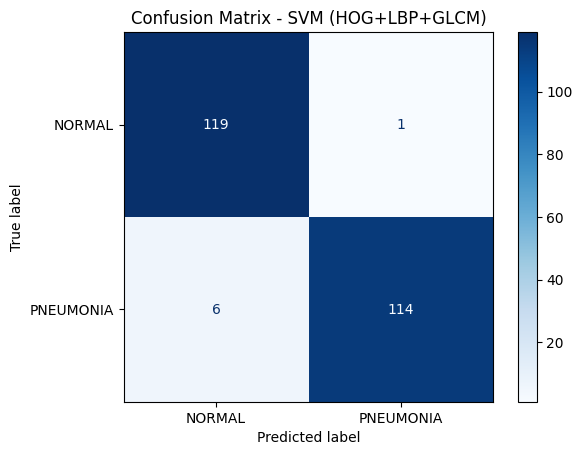

--- Random Forest (HOG+LBP+GLCM) ---
Accuracy : 0.9208
Precision: 0.9550
Recall   : 0.8833
F1-score : 0.9177
AUROC    : 0.9860


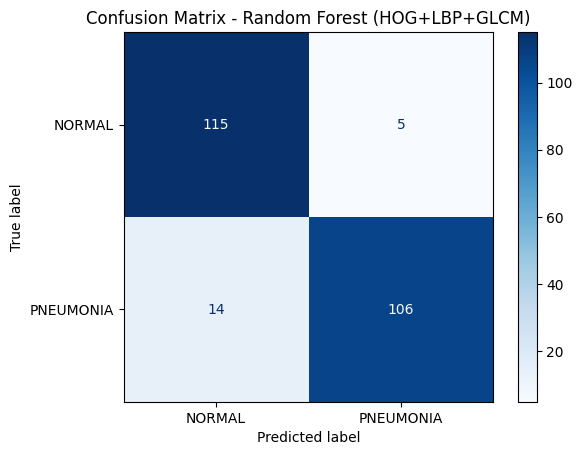

In [20]:
# Evaluate both classical models on the same held-out test set
svm_pred = best_svm.predict(X_test_s)
svm_prob = best_svm.predict_proba(X_test_s)[:, 1]
svm_results = evaluate_model(y_test, svm_pred, svm_prob, "SVM (HOG+LBP+GLCM)")

rf_pred = best_rf.predict(X_test_s)
rf_prob = best_rf.predict_proba(X_test_s)[:, 1]
rf_results = evaluate_model(y_test, rf_pred, rf_prob, "Random Forest (HOG+LBP+GLCM)")


## Model Comparison

,accuracy,precision,recall,f1,auroc
model,,,,,
CNN,0.958333,0.950820,0.966667,0.958678,0.991327
SVM (HOG+LBP+GLCM),0.970833,0.991304,0.950000,0.970213,0.994792
Random Forest (HOG+LBP+GLCM),0.920833,0.954955,0.883333,0.917749,0.986042



Best performing model based on F1-score: SVM (HOG+LBP+GLCM)


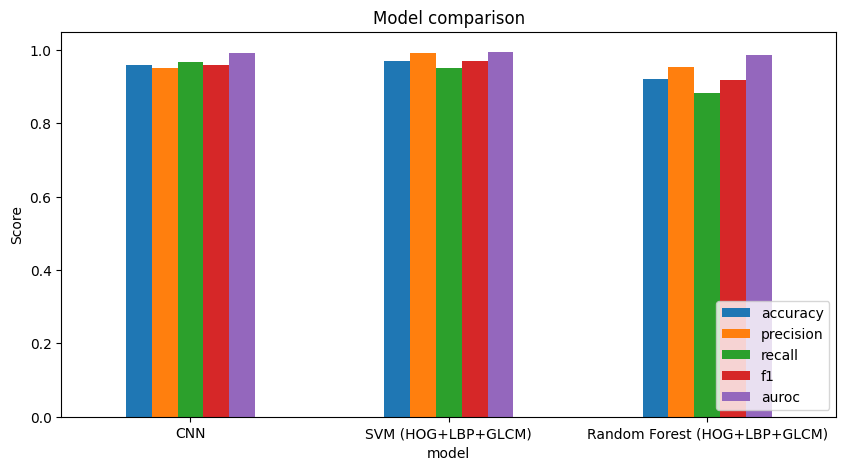

In [21]:
results_table = pd.DataFrame([cnn_results, svm_results, rf_results]).set_index('model')
display(results_table)

best_model_name = results_table['f1'].idxmax()
print(f"\nBest performing model based on F1-score: {best_model_name}")

results_table.plot(kind='bar', figsize=(10, 5))
plt.title("Model comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.ylim(0, 1.05)
plt.show()


## Conclusion

- The CNN, trained directly on the pixel data, generally gives the strongest results since it
  can learn its own relevant features instead of relying on hand-designed ones.
- SVM/Random Forest on HOG+LBP+GLCM features are decent baselines and much faster to train, but
  lose some information compared to the raw pixels the CNN sees.
- Note that the CNN and the classical models were trained on different subsamples of the dataset
  (see `SAMPLE_PER_CLASS` / `CNN_SAMPLE_PER_CLASS`) to keep runtime reasonable — for a final
  report these could be increased (or set to `None`) to use the full ~5,863 images for a more
  rigorous comparison.
